# Alquiler — 02 Limpieza y preparación

Limpieza de los alquileres de Moscú para predecir `monthly_rent_rub` **a futuro**.
La organización es la de encontrar, corregir y volver a mirar:

- **Paso 1 «encontrar»**: diagnóstico sobre la base enriquecida, sin modificar datos.
- **Paso 2 «refregar»**: tipos, reglas de negocio, fuga, joins con rezago, división temporal y atípicos.
- **Paso 3 «enjuagar»**: repetir el diagnóstico sobre el resultado, con asserts.

Tres criterios ordenan todo el notebook. La variable objetivo se trabaja **cruda, en
rublos**: su asimetría (skew = 1,82) es la forma propia de los precios, con alquileres
centrales reales en la cola, y forzarla a una forma simétrica borraría información del
mercado. La división es **temporal** —se entrena con el pasado y se evalúa con el
futuro— porque un corte aleatorio mezclaría meses futuros en el entrenamiento y
sobreestimaría el desempeño. Y todo parámetro que se aprende de los datos (los fences
de atípicos) se calcula **solo con el pasado** y se aplica hacia adelante, igual que
ocurrirá al predecir meses que todavía no existen.

## 0. Entorno

Correr con el kernel **(.venv)**. Si falta el entorno:

```
source .venv/bin/activate
pip install -r requirements.txt
```

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

DATA_DIR = Path("..") / "data"
OUT_DIR = DATA_DIR / "processed"
TARGET = "monthly_rent_rub"
CORTE_TEST = "2025-01-01"  # el futuro: test desde enero de 2025

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)

print("pandas", pd.__version__, "| numpy", np.__version__)
print("DATA_DIR:", DATA_DIR.resolve(), "| existe:", DATA_DIR.exists())

pandas 3.0.6 | numpy 2.5.4
DATA_DIR: /Users/tomasmontilla/workspace/facultad/Moscow-real-estate-market--Sales-and-rentals/data | existe: True


## Paso 1 — «Encontrar la suciedad» (solo diagnóstico)

Se carga la base y se enriquece con sus dos contextos —el mensual por distrito y el
de la estación de metro— para diagnosticar sobre la misma información que después
va a consumir el modelo. En este paso no se modifica ninguna fila: se mide.

In [2]:
rentals = pd.read_csv(DATA_DIR / "rentals.csv", parse_dates=["date_posted"])
monthly = pd.read_csv(DATA_DIR / "district_prices_monthly.csv")
metro = pd.read_csv(DATA_DIR / "metro_stations.csv")

rentals["year_month"] = rentals["date_posted"].dt.strftime("%Y-%m")
print(f"rentals: {len(rentals):,} filas x {rentals.shape[1]} columnas | "
      f"{rentals['date_posted'].min().date()} -> {rentals['date_posted'].max().date()}")
print(f"monthly: {monthly.shape} | {monthly['year_month'].min()} -> {monthly['year_month'].max()} | "
      f"grilla completa distrito-mes: {len(monthly) == monthly['district'].nunique() * monthly['year_month'].nunique()}")
print(f"metro:   {metro.shape} | estaciones unicas: {metro['station_name'].nunique()}")

n0 = len(rentals)
df_diag = rentals.merge(monthly, on=["district", "year_month"], how="left",
                        suffixes=("", "_dup"), indicator="m_distrito_mes")
assert len(df_diag) == n0 and (df_diag["m_distrito_mes"] == "both").all()
df_diag = df_diag.drop(columns=["m_distrito_mes", "okrug_dup"])
metro_r = metro.rename(columns={"station_name": "metro_station", "line": "station_line",
                                "lat": "station_lat", "lon": "station_lon",
                                "to_center_km": "station_to_center_km"})
df_diag = df_diag.merge(metro_r, on="metro_station", how="left", indicator="m_metro")
assert len(df_diag) == n0 and (df_diag["m_metro"] == "both").all()
df_diag = df_diag.drop(columns=["m_metro"])
print(f"base enriquecida para diagnosticar: {df_diag.shape[0]:,} filas x {df_diag.shape[1]} columnas "
      f"(sin perder filas: {len(df_diag) == n0})")

rentals: 20,000 filas x 23 columnas | 2021-01-01 -> 2026-04-29
monthly: (9804, 13) | 2020-01 -> 2026-04 | grilla completa distrito-mes: True
metro:   (104, 6) | estaciones unicas: 104
base enriquecida para diagnosticar: 20,000 filas x 38 columnas (sin perder filas: True)


In [3]:
filas = []
for col in df_diag.columns:
    s = df_diag[col]
    filas.append({"columna": col, "dtype": str(s.dtype), "n_nulos": int(s.isna().sum()),
                  "n_unicos": int(s.nunique())})
display(pd.DataFrame(filas))
print("filas duplicadas completas:", int(df_diag.duplicated().sum()),
      "| ids duplicados:", int(df_diag["id"].duplicated().sum()),
      "| nulos totales:", int(df_diag.isna().sum().sum()))

,columna,dtype,n_nulos,n_unicos
0,id,str,0,20000
1,date_posted,datetime64[us],0,1945
2,district,str,0,129
3,okrug,str,0,11
4,lat,float64,0,15985
5,lon,float64,0,16678
6,total_area,float64,0,695
7,rooms,int64,0,4
8,floor,int64,0,22
9,total_floors,int64,0,5


filas duplicadas completas: 0 | ids duplicados: 0 | nulos totales: 0


La base llega sin nulos y sin duplicados, así que el trabajo de limpieza no pasa por
imputar ni por borrar copias: pasa por la forma de las distribuciones, por las
relaciones entre columnas y por el tiempo. Esos tres frentes se miden a continuación.

In [4]:
num_diag = df_diag.select_dtypes(include=np.number)
desc = num_diag.describe().T
desc["skew"] = num_diag.skew().round(2)
display(desc[[TARGET, "total_area", "metro_distance_min", "to_center_km"]].round(2)
        if False else desc.loc[[TARGET, "total_area", "metro_distance_min", "to_center_km"]].round(2))
print(f"{TARGET}: media={df_diag[TARGET].mean():,.0f} | mediana={df_diag[TARGET].median():,.0f} "
      f"| skew={float(df_diag[TARGET].skew()):.2f} -> cola derecha propia de precios; se conserva cruda")

meses = df_diag.groupby(df_diag["date_posted"].dt.to_period("M")).size()
print(f"meses con avisos: {len(meses)} ({meses.index.min()} -> {meses.index.max()}) | "
      f"avisos por mes entre {meses.min()} y {meses.max()}: hay historia suficiente para cortar por fecha")

,count,mean,std,min,25%,50%,75%,max,skew
monthly_rent_rub,20000.0,52432.86,30003.24,6800.00,32800.00,45800.00,64400.00,300700.00,1.82
total_area,20000.0,55.39,12.74,22.10,45.70,53.80,63.30,104.60,0.58
metro_distance_min,20000.0,152.39,167.80,0.00,33.00,103.00,198.00,966.00,1.96
to_center_km,20000.0,16.36,12.80,0.02,9.04,13.23,18.03,71.06,2.12


monthly_rent_rub: media=52,433 | mediana=45,800 | skew=1.82 -> cola derecha propia de precios; se conserva cruda
meses con avisos: 64 (2021-01 -> 2026-04) | avisos por mes entre 278 y 361: hay historia suficiente para cortar por fecha


In [5]:
# Colas exploratorias (solo diagnostico: los umbrales utiles seran los del pasado, en el Paso 2)
filas_out = []
for col in [TARGET, "total_area", "metro_distance_min", "to_center_km", "rent_per_sqm"]:
    s = df_diag[col]
    lo, hi = s.quantile(0.25) - 1.5 * stats.iqr(s), s.quantile(0.75) + 1.5 * stats.iqr(s)
    filas_out.append({"variable": col, "fuera_de_fences": int(((s < lo) | (s > hi)).sum()),
                      "pct": round(float(((s < lo) | (s > hi)).mean() * 100), 2),
                      "fence_superior": round(float(hi), 1), "maximo": round(float(s.max()), 1)})
display(pd.DataFrame(filas_out))
print("Los extremos altos del alquiler son avisos centrales reales (distritos caros, 70-90 m2),")
print("no errores de carga: las reglas fisicas del Paso 2 dan 0 violaciones; la unica excepcion es")
print("temporal (publicacion anterior al building_year) y se resuelve en ese mismo paso.")

,variable,fuera_de_fences,pct,fence_superior,maximo
0,monthly_rent_rub,936,4.68,111800.0,300700.0
1,total_area,174,0.87,89.7,104.6
2,metro_distance_min,1416,7.08,445.5,966.0
3,to_center_km,1905,9.53,31.5,71.1
4,rent_per_sqm,1001,5.00,1871.5,4264.0


Los extremos altos del alquiler son avisos centrales reales (distritos caros, 70-90 m2),
no errores de carga: las reglas fisicas del Paso 2 dan 0 violaciones; la unica excepcion es
temporal (publicacion anterior al building_year) y se resuelve en ese mismo paso.


In [6]:
# Relaciones que el Paso 2 va a tener que resolver, medidas antes de tocar nada
corr_diag = df_diag[["cbr_key_rate_pct", "avg_mortgage_rate_pct", "year_opened",
                     "metro_distance_min", "to_center_km", "total_area", "rooms",
                     "rental_price_per_sqm_monthly", "secondary_price_per_sqm",
                     "newbuild_price_per_sqm", "rent_per_sqm", TARGET]].corr(numeric_only=True)
pares = pd.DataFrame([
    {"par": "tasa hipotecaria vs tasa clave", "r": round(float(corr_diag.loc["cbr_key_rate_pct", "avg_mortgage_rate_pct"]), 3)},
    {"par": "anio de apertura vs antiguedad de la estacion", "r": round(float(pd.Series(df_diag["date_posted"].dt.year - df_diag["year_opened"]).corr(df_diag["year_opened"])), 3)},
    {"par": "minutos al metro vs distancia al centro", "r": round(float(corr_diag.loc["metro_distance_min", "to_center_km"]), 3)},
    {"par": "superficie vs ambientes", "r": round(float(corr_diag.loc["total_area", "rooms"]), 3)},
    {"par": "precio distrital alquiler vs venta (secundario)", "r": round(float(corr_diag.loc["rental_price_per_sqm_monthly", "secondary_price_per_sqm"]), 3)},
    {"par": "precio distrital alquiler vs venta (obra nueva)", "r": round(float(corr_diag.loc["rental_price_per_sqm_monthly", "newbuild_price_per_sqm"]), 3)},
    {"par": "rent_per_sqm vs objetivo (fuga)", "r": round(float(corr_diag.loc["rent_per_sqm", TARGET]), 3)},
    {"par": "precio distrital del mes vs objetivo", "r": round(float(corr_diag.loc["rental_price_per_sqm_monthly", TARGET]), 3)},
])
display(pares)
print(f"linea del aviso == linea de la estacion en el {(df_diag['metro_line'] == df_diag['station_line']).mean():.0%} de los casos")
print(f"distritos con mas de un okrug: {int((df_diag.groupby('district')['okrug'].nunique() > 1).sum())} de {df_diag['district'].nunique()}"
      " -> el distrito determina al okrug")
print(f"max |rent_per_sqm - alquiler/superficie| = "
      f"{(df_diag['rent_per_sqm'] - df_diag[TARGET] / df_diag['total_area']).abs().max():.2f} RUB (redondeo): deriva del target")

,par,r
0,tasa hipotecaria vs tasa clave,1.000
1,anio de apertura vs antiguedad de la estacion,-0.997
2,minutos al metro vs distancia al centro,0.904
3,superficie vs ambientes,0.883
4,precio distrital alquiler vs venta (secundario),1.000
5,precio distrital alquiler vs venta (obra nueva),0.998
6,rent_per_sqm vs objetivo (fuga),0.893
7,precio distrital del mes vs objetivo,0.772


linea del aviso == linea de la estacion en el 100% de los casos
distritos con mas de un okrug: 0 de 129 -> el distrito determina al okrug
max |rent_per_sqm - alquiler/superficie| = 2.09 RUB (redondeo): deriva del target


## Paso 2 — «Refregar» (aplicar la limpieza)

### Tipos y fechas

`date_posted` queda como fecha y de ella se derivan `year_month` (llave del contexto
mensual) y `year_month_dt` (eje para cortar por tiempo). Los booleanos pasan a 0/1 y
las categóricas a `category`, con `rooms` incluida: tiene solo cuatro valores
(1 a 4) y su efecto sobre el alquiler no crece en pasos iguales, así que tratarla
como continua impondría una recta donde hay escalones.

La objetivo no se transforma. Su skew de 1,82 con media de 52.433 RUB sobre una
mediana de 45.800 RUB describe un mercado con un segmento premium real, no un error
de medición; trabajar en rublos además mantiene cada coeficiente y cada error
directamente interpretable en la moneda en que se cobra el alquiler. Si más adelante
el diagnóstico de residuos de un modelo pidiera otra forma, esa será una decisión de
modelado sobre residuos observados, no una corrección anticipada en la limpieza.

In [7]:
df = rentals.copy()
df["year_month_dt"] = pd.to_datetime(df["year_month"])
for c in ["furnished", "pets_allowed"]:
    df[c] = df[c].astype("int8")
for c in ["district", "building_type", "renovation", "metro_station", "metro_line", "rooms"]:
    df[c] = df[c].astype("category")

print(f"objetivo cruda: skew={float(stats.skew(df[TARGET])):.2f} | "
      f"media={df[TARGET].mean():,.0f} RUB | mediana={df[TARGET].median():,.0f} RUB (sin transformar)")
print("tipos resultantes:")
display(df.dtypes.rename("dtype").to_frame())

objetivo cruda: skew=1.82 | media=52,433 RUB | mediana=45,800 RUB (sin transformar)
tipos resultantes:


,dtype
id,str
date_posted,datetime64[us]
district,category
okrug,str
lat,float64
lon,float64
total_area,float64
rooms,category
floor,int64
total_floors,int64


### Reglas de negocio: lo imposible no se negocia con la distribución

Un piso no puede superar los pisos del edificio ni un alquiler ser negativo, en
ningún mes y en ningún distrito. Por eso estas reglas se aplican sobre las 20.000
filas, antes de cualquier división: no aprenden nada de los datos y no pueden
filtrar información entre períodos.

Ocho de las nueve reglas no encuentran ningún caso. La excepción son 339 avisos
(1,7 %) publicados entre 1 y 3 años antes del `building_year` de su edificio, todos
en edificios `monolith` o `modern_panel` terminados entre 2022 y 2024. Conservarlos
con una marca dejaría dentro del entrenamiento filas cuya antigüedad de edificio es
negativa y cuya relación superficie–precio corresponde a otra etapa del inmueble;
corregir el año fabricaría un dato que no existe. Se excluyen, y el costo queda a la
vista: son todos casos del período de entrenamiento, ninguno del futuro a evaluar.

In [8]:
anio_pub = df["date_posted"].dt.year
reglas = {
    "floor > total_floors": df["floor"] > df["total_floors"],
    "floor < 1 o total_floors < 1": (df["floor"] < 1) | (df["total_floors"] < 1),
    "total_area <= 0": df["total_area"] <= 0,
    "alquiler <= 0": df[TARGET] <= 0,
    "rooms fuera de 1-4": ~df["rooms"].isin([1, 2, 3, 4]),
    "deposit_months fuera de 0-2": ~df["deposit_months"].isin([0, 1, 2]),
    "building_year posterior a la publicacion": df["building_year"] > anio_pub,
    "distancias negativas": (df["metro_distance_min"] < 0) | (df["to_center_km"] < 0),
    "lat/lon fuera de Moscu": ~df["lat"].between(55.0, 56.2) | ~df["lon"].between(36.5, 38.0),
}
display(pd.Series({k: int(v.sum()) for k, v in reglas.items()}, name="violaciones").to_frame())

invalidos = reglas["building_year posterior a la publicacion"]
print(f"excluidos por publicacion anterior al building_year: {int(invalidos.sum())} "
      f"({invalidos.mean():.2%}) | en train (<{CORTE_TEST}): {int((invalidos & (df['date_posted'] < CORTE_TEST)).sum())} "
      f"| en test (>={CORTE_TEST}): {int((invalidos & (df['date_posted'] >= CORTE_TEST)).sum())}")
df = df.loc[~invalidos].copy()
otras = [k for k, v in reglas.items() if k != "building_year posterior a la publicacion"]
assert all(int(v.sum()) == 0 for k, v in reglas.items() if k in otras)
print(f"base tras reglas de negocio: {len(df):,} filas")

,violaciones
floor > total_floors,0
floor < 1 o total_floors < 1,0
total_area <= 0,0
alquiler <= 0,0
rooms fuera de 1-4,0
deposit_months fuera de 0-2,0
building_year posterior a la publicacion,339
distancias negativas,0
lat/lon fuera de Moscu,0


excluidos por publicacion anterior al building_year: 339 (1.70%) | en train (<2025-01-01): 339 | en test (>=2025-01-01): 0
base tras reglas de negocio: 19,661 filas


### Fuga y columnas que no aportan información nueva

`rent_per_sqm` sale del dataset limpio: es el alquiler dividido por la superficie,
con diferencia máxima de 2,09 RUB por redondeo respecto de esa identidad y
correlación 0,89 con la objetivo. Usarla como predictora sería explicarle al modelo
el precio con el propio precio.

`okrug` también sale. Cada uno de los 129 distritos pertenece a un único `okrug`, de
modo que el distrito ya contiene esa información en versión más fina: el `okrug`
explica el 49,2 % de la varianza del alquiler y el distrito el 60,4 %, pero ese
49,2 % está adentro del 60,4 %, no se le suma. Conservar ambas solo crearía
columnas que son combinaciones exactas de otras al momento de codificar.

In [9]:
identidad = (df["rent_per_sqm"] - df[TARGET] / df["total_area"]).abs().max()
assert identidad <= 5
assert int((df.groupby("district", observed=True)["okrug"].nunique() > 1).sum()) == 0 if "okrug" in df else True
print(f"rent_per_sqm: max |diferencia con alquiler/superficie| = {identidad:.2f} RUB, "
      f"r con la objetivo = {df['rent_per_sqm'].corr(df[TARGET]):.2f} -> sale por fuga")
print("okrug: 129/129 distritos con un unico okrug -> sale, su informacion queda contenida en district")
df = df.drop(columns=["rent_per_sqm", "okrug"])
print(f"columnas tras quitar fuga y redundancia geografica gruesa: {df.shape[1]}")

rent_per_sqm: max |diferencia con alquiler/superficie| = 2.09 RUB, r con la objetivo = 0.89 -> sale por fuga
okrug: 129/129 distritos con un unico okrug -> sale, su informacion queda contenida en district
columnas tras quitar fuga y redundancia geografica gruesa: 22


### Joins con rezago: predecir el futuro con información del pasado

El contexto distrito-mes es la señal geográfica más fuerte del problema: el precio
de alquiler del distrito correlaciona 0,77 con el alquiler del aviso y explica por
sí solo cerca del 60 % de su varianza en una regresión simple. Pero ese valor, tal
como viene, resume **todo** el mes del aviso, incluidos avisos posteriores a la
fecha de publicación. Usarlo así para predecir un mes futuro equivaldría a conocer
el cierre de un mercado que todavía no ocurrió.

Por eso todo el bloque mensual entra **rezagado un mes**: para un aviso de marzo se
usa el contexto cerrado de febrero. El costo medido de ese cuidado es nulo en esta
base —la correlación con la objetivo es 0,772 en versión contemporánea y 0,772 en
versión rezagada, porque el nivel distrital se mueve despacio— y no se pierde
ninguna fila ni aparece ningún nulo, porque la serie mensual arranca en 2020-01 y
los avisos en 2021-01. Del bloque rezagado quedan el precio de alquiler distrital,
las dos variaciones mensuales de precios de venta, los tres volúmenes de avisos y la
tasa clave. Los precios de venta por m² no entran ni siquiera rezagados:
correlacionan 0,998–1,000 con el precio de alquiler distrital, de modo que repetirían
la misma columna con otra escala. La tasa hipotecaria tampoco: es la tasa clave más
2,5 puntos en todos los meses (r = 1,000), una identidad y no una señal adicional.

Del metro se conservan la estación, su distancia al centro y su antigüedad al
momento de la publicación. El año de apertura sale porque la antigüedad lo contiene
con el signo cambiado (r = −0,997), y las coordenadas de la estación salen porque
son una función de la estación misma: no agregan nada que la estación no diga.

In [10]:
LAG_COLS = ["rental_price_per_sqm_monthly", "secondary_mom_change_pct", "newbuild_mom_change_pct",
            "n_listings_secondary", "n_listings_newbuild", "n_listings_rental", "cbr_key_rate_pct"]
monthly_lag = (monthly.sort_values(["district", "year_month"])
               .drop(columns=["okrug", "secondary_price_per_sqm", "newbuild_price_per_sqm",
                              "avg_mortgage_rate_pct"])
               .copy())
for c in LAG_COLS:
    monthly_lag[c] = monthly_lag.groupby("district")[c].shift(1)
monthly_lag = monthly_lag.rename(columns={c: f"{c}_lag1" for c in LAG_COLS})

n0 = len(df)
df = df.merge(monthly_lag, on=["district", "year_month"], how="left", validate="many_to_one")
assert len(df) == n0
metro_r2 = metro.rename(columns={"station_name": "metro_station", "line": "station_line",
                                 "lat": "station_lat", "lon": "station_lon",
                                 "to_center_km": "station_to_center_km"})
df = df.merge(metro_r2, on="metro_station", how="left", validate="many_to_one")
assert len(df) == n0
assert (df["metro_line"].astype(str) == df["station_line"].astype(str)).all()
df["estacion_antiguedad"] = df["date_posted"].dt.year - df["year_opened"]
df = df.drop(columns=["station_line", "station_lat", "station_lon", "year_opened"])

lag_cols = [f"{c}_lag1" for c in LAG_COLS]
print(f"joins sin perder filas: {n0:,} -> {len(df):,} | nulos nuevos en el bloque rezagado: "
      f"{int(df[lag_cols].isna().sum().sum())} en {len(lag_cols)} columnas")
print(f"r(precio distrital rezagado, objetivo) = {df['rental_price_per_sqm_monthly_lag1'].corr(df[TARGET]):.3f}")
print(f"base enriquecida y limpia: {df.shape[0]:,} filas x {df.shape[1]} columnas")
display(df[["id", "date_posted", "district", "metro_station", TARGET] + lag_cols[:2]].head(3))

joins sin perder filas: 19,661 -> 19,661 | nulos nuevos en el bloque rezagado: 0 en 7 columnas
r(precio distrital rezagado, objetivo) = 0.772
base enriquecida y limpia: 19,661 filas x 31 columnas


,id,date_posted,district,metro_station,monthly_rent_rub,rental_price_per_sqm_monthly_lag1,secondary_mom_change_pct_lag1
0,R000001,2025-01-16,Nagatinsky Zaton,Ugreshskaya,26200,1392.0,1.30
1,R000002,2022-11-12,Chertanovo Severnoye,Kuznetsky Most,37200,1067.0,-2.59
2,R000003,2026-03-06,Savyolovsky,Rizhskaya,96700,1502.0,-2.87


Dos pares de predictoras quedan deliberadamente conviviendo en la base limpia.
Los minutos al metro y la distancia al centro correlacionan 0,90, y la superficie
con los ambientes 0,88: comparten gran parte de la historia, pero cada una conserva
una porción propia (entre el 18 % y el 22 % de varianza no compartida) que una
correlación suelta no alcanza a juzgar. Recién con la matriz de variables armada se
puede medir cuánto infla cada una la varianza de los coeficientes de la otra, y esa
medición pertenece a la etapa de ingeniería de características y modelado. Podar
acá, a ciegas, arriesga borrar señal que después no se recupera.

Las categóricas de alta cardinalidad también quedan tal cual, como `category`:
`district` con 129 niveles y `metro_station` con 104 están presentes en ambos
períodos, sin categorías nuevas en el futuro y con apoyos mínimos de 90 y 77 avisos
por nivel en el pasado. Cómo se codifican —y si conviene codificarlas— es una
decisión de representación que se toma con el modelo a la vista, no en la limpieza.

### División temporal: entrenar con el pasado, evaluar con el futuro

El corte es el 1 de enero de 2025. El entrenamiento reúne los avisos de 2021 a 2024
y la evaluación los de enero de 2025 a abril de 2026: dieciséis meses completos, un
24,6 % de la base limpia, por encima del quinto que una evaluación seria necesita
para estimar el error sin gastar la historia. La mediana del alquiler pasa de
45.000 RUB en el pasado a 48.500 RUB en el futuro, y ese desplazamiento es parte de
lo que la evaluación debe revelar: un modelo que solo funciona si el futuro se
parece al pasado en promedio no está prediciendo, está repitiendo.

Ninguna fila cruza el corte en la dirección prohibida y ningún identificador se
repite entre ambos lados.

train 14,820 avisos | 2021-01-01 -> 2024-12-31 | mediana 45,000 RUB
test  4,841 avisos | 2025-01-01 -> 2026-04-29 | mediana 48,500 RUB | 24.6% de la base limpia
sin solape de id: True


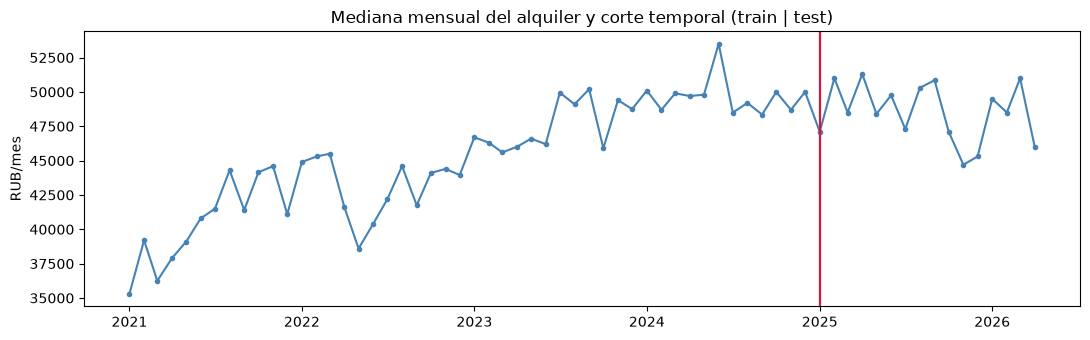

In [11]:
corte = pd.Timestamp(CORTE_TEST)
train = df.loc[df["date_posted"] < corte].copy()
test = df.loc[df["date_posted"] >= corte].copy()

assert len(train) + len(test) == len(df)
assert train["date_posted"].max() < corte <= test["date_posted"].min()
assert set(train["id"]).isdisjoint(test["id"])
assert len(test) / len(df) >= 0.20
print(f"train {len(train):,} avisos | {train['date_posted'].min().date()} -> {train['date_posted'].max().date()} "
      f"| mediana {train[TARGET].median():,.0f} RUB")
print(f"test  {len(test):,} avisos | {test['date_posted'].min().date()} -> {test['date_posted'].max().date()} "
      f"| mediana {test[TARGET].median():,.0f} RUB | {len(test) / len(df):.1%} de la base limpia")
print(f"sin solape de id: {set(train['id']).isdisjoint(test['id'])}")

fig, ax = plt.subplots(figsize=(11, 3.5))
serie = df.groupby("year_month_dt")[TARGET].median()
ax.plot(serie.index, serie.values, marker="o", markersize=3, color="steelblue")
ax.axvline(corte, color="crimson", lw=1.6)
ax.set_title("Mediana mensual del alquiler y corte temporal (train | test)")
ax.set_ylabel("RUB/mes")
plt.tight_layout()
plt.show()

### Atípicos: winsorizar el pasado, evaluar el futuro intacto

Sobre la objetivo cruda del entrenamiento, los fences de IQR dejan fuera a 720
avisos (4,9 %) por encima del tope. Esos avisos no son errores —son el segmento
premium del centro— pero su peso sobre una suma de cuadrados es desproporcionado:
con ellos, el desvío del alquiler de entrenamiento es de 29.561 RUB y la
curtosis de 5,76. La winsorización los trae hasta el fence sin borrarlos: conserva
las 14.820 filas, baja el skew de 1,85 a 0,80 y la curtosis a 0,02, y
mejora levemente la relación de referencia entre superficie y alquiler.

Los fences se calculan **solo con el entrenamiento** y se aplican solo ahí. El
objetivo del test queda crudo, con su máximo real: recortarlo también recortaría
302 avisos genuinos (6,2 %) y la evaluación mediría un futuro editado a la medida
del pasado. Las predictoras continuas no se winsorizan: sus colas son geografía
—avisos lejos del centro y lejos del metro— y comprimirlas borraría justamente el
segmento periférico. En su lugar, cada fila lleva marcas que señalan si cae fuera
de los fences aprendidos en el entrenamiento, para que la etapa siguiente pueda
mirar esos casos sin que hayan sido alterados.

In [12]:
y_train = train[TARGET].astype(float)
q1, q3 = y_train.quantile(0.25), y_train.quantile(0.75)
fence_lo, fence_hi = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
n_winsor = int((y_train > fence_hi).sum() + (y_train < fence_lo).sum())

def resumen_target(nombre, s):
    return {"conjunto": nombre, "n": len(s), "media": round(float(s.mean()), 0),
            "mediana": round(float(s.median()), 0), "std": round(float(s.std()), 0),
            "skew": round(float(stats.skew(s)), 2),
            "kurtosis": round(float(stats.kurtosis(s)), 2), "maximo": round(float(s.max()), 0)}

antes = resumen_target("train crudo", y_train)
train["target_winsorizado"] = ((y_train < fence_lo) | (y_train > fence_hi)).astype("int8")
train[TARGET] = y_train.clip(fence_lo, fence_hi)
test["target_winsorizado"] = np.int8(0)
despues = resumen_target("train winsorizado", train[TARGET])
crudo_test = resumen_target("test (crudo, para evaluar)", test[TARGET])
display(pd.DataFrame([antes, despues, crudo_test]))
print(f"fences de train: [{fence_lo:,.0f}, {fence_hi:,.0f}] RUB | avisos winsorizados en train: "
      f"{n_winsor} ({n_winsor / len(train):.1%}) | filas conservadas: {len(train):,}")
assert int(test["target_winsorizado"].sum()) == 0

def iqr_flags(base, ref):
    flags = pd.DataFrame(index=base.index)
    for c in ["total_area", "metro_distance_min", "to_center_km"]:
        x = ref[c]
        lo_c = x.quantile(0.25) - 1.5 * stats.iqr(x)
        hi_c = x.quantile(0.75) + 1.5 * stats.iqr(x)
        flags[f"flag_outlier_{c}"] = ((base[c] < lo_c) | (base[c] > hi_c)).astype("int8")
    return flags

train = pd.concat([train, iqr_flags(train, train)], axis=1)
test = pd.concat([test, iqr_flags(test, train)], axis=1)
print("filas marcadas en test con fences de train (solo marcas, valores intactos):")
display(test[[c for c in test.columns if c.startswith("flag_outlier")]].sum().rename("filas").to_frame())

,conjunto,n,media,mediana,std,skew,kurtosis,maximo
0,train crudo,14820,51447.0,45000.0,29561.0,1.85,5.76,300700.0
1,train winsorizado,14820,49932.0,45000.0,24625.0,0.80,0.02,108550.0
2,"test (crudo, para evaluar)",4841,55457.0,48500.0,31251.0,1.76,5.20,289300.0


fences de train: [-13,450, 108,550] RUB | avisos winsorizados en train: 720 (4.9%) | filas conservadas: 14,820
filas marcadas en test con fences de train (solo marcas, valores intactos):


,filas
flag_outlier_total_area,43
flag_outlier_metro_distance_min,360
flag_outlier_to_center_km,461


## Paso 3 — «Enjuagar y repetir» (re-chequeo sobre lo limpio)

Se repite el diagnóstico inicial sobre el resultado. Todo lo que el Paso 1 encontró
tiene que aparecer resuelto o transformado según lo aplicado en el Paso 2; si
surgiera algo nuevo, correspondería volver al Paso 2 en lugar de corregirlo acá en
silencio.

In [13]:
clean = df.copy()
chequeos = pd.DataFrame([
    {"chequeo": "nulos en clean / train / test",
     "resultado": f"{int(clean.isna().sum().sum())} / {int(train.isna().sum().sum())} / {int(test.isna().sum().sum())}"},
    {"chequeo": "duplicados exactos en clean", "resultado": int(clean.duplicated().sum())},
    {"chequeo": "filas clean / train / test",
     "resultado": f"{len(clean):,} / {len(train):,} / {len(test):,}"},
    {"chequeo": "solape de id train-test", "resultado": len(set(train["id"]) & set(test["id"]))},
    {"chequeo": "fecha maxima train < corte <= fecha minima test",
     "resultado": bool(train["date_posted"].max() < corte <= test["date_posted"].min())},
    {"chequeo": "columnas de fuga o redundancia presentes",
     "resultado": [c for c in ["rent_per_sqm", "okrug", "avg_mortgage_rate_pct_lag1",
                               "secondary_price_per_sqm", "newbuild_price_per_sqm",
                               "year_opened", "station_lat", "station_lon"] if c in clean.columns]},
    {"chequeo": "target de test winsorizado (debe ser 0)", "resultado": int(test["target_winsorizado"].sum())},
    {"chequeo": "maximo del test crudo (RUB)", "resultado": f"{test[TARGET].max():,.0f}"},
    {"chequeo": "skew objetivo train winsorizado / test crudo",
     "resultado": f"{float(stats.skew(train[TARGET])):.2f} / {float(stats.skew(test[TARGET])):.2f}"},
])
display(chequeos)
assert int(clean.isna().sum().sum()) == 0 and int(train.isna().sum().sum()) == 0 and int(test.isna().sum().sum()) == 0
assert int(clean.duplicated().sum()) == 0 and len(set(train["id"]) & set(test["id"])) == 0
assert not [c for c in ["rent_per_sqm", "okrug", "secondary_price_per_sqm", "newbuild_price_per_sqm",
                        "year_opened", "station_lat", "station_lon"] if c in clean.columns]
assert int(test["target_winsorizado"].sum()) == 0
print("Re-chequeo completo: todo lo diagnosticado quedo resuelto o aplicado; no hace falta una segunda vuelta.")

,chequeo,resultado
0,nulos en clean / train / test,0 / 0 / 0
1,duplicados exactos en clean,0
2,filas clean / train / test,"19,661 / 14,820 / 4,841"
3,solape de id train-test,0
4,fecha maxima train < corte <= fecha minima test,True
5,columnas de fuga o redundancia presentes,[]
6,target de test winsorizado (debe ser 0),0
7,maximo del test crudo (RUB),"289,300"
8,skew objetivo train winsorizado / test crudo,0.80 / 1.76


Re-chequeo completo: todo lo diagnosticado quedo resuelto o aplicado; no hace falta una segunda vuelta.


## Guardado

Se guardan tres artefactos en `data/processed/`. La base limpia previa a la división
conserva el objetivo crudo en las 19.661 filas que superaron las reglas de negocio;
el entrenamiento lleva el objetivo winsorizado con los fences de su propio período;
y la evaluación conserva el objetivo crudo, tal como ocurrió. Los originales de
`data/` no se modifican.

In [14]:
OUT_DIR.mkdir(parents=True, exist_ok=True)
clean.to_csv(OUT_DIR / "rentals_clean.csv", index=False)
train.to_csv(OUT_DIR / "rentals_train.csv", index=False)
test.to_csv(OUT_DIR / "rentals_test.csv", index=False)
for f in ["rentals_clean.csv", "rentals_train.csv", "rentals_test.csv"]:
    d = pd.read_csv(OUT_DIR / f)
    print(f"{f}: {d.shape[0]:,} x {d.shape[1]} | rent_per_sqm presente: {'rent_per_sqm' in d.columns} "
          f"| okrug presente: {'okrug' in d.columns}")

rentals_clean.csv: 19,661 x 31 | rent_per_sqm presente: False | okrug presente: False
rentals_train.csv: 14,820 x 35 | rent_per_sqm presente: False | okrug presente: False
rentals_test.csv: 4,841 x 35 | rent_per_sqm presente: False | okrug presente: False


## Cierre

La base que sale de esta limpieza tiene 19.661 avisos entre 2021 y 2026, con el
alquiler en rublos tal como se publicó, el contexto del distrito rezagado un mes
para que ninguna fila use información de su propio futuro, y una evaluación que
empieza en 2025 con el objetivo intacto. Entrenan 14.820 avisos con la cola premium
contenida en el fence de su propio período; evalúan 4.841 avisos crudos.

Quedan listas para la etapa siguiente las preguntas de representación: cómo se
codifican los 129 distritos y las 104 estaciones, cuánto aporta cada distancia
cuando la otra ya está en la matriz, y qué forma funcional toma cada continua. Esta
limpieza no anticipa esas respuestas: entrega los datos ordenados, fechados y sin
fugas para que se tomen con el modelo a la vista.